In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yachaymarketing/text-coordinates-regions")

print("Path to dataset files:", path)

/home/roman/Documents/university/thesis/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /home/roman/.cache/kagglehub/datasets/yachaymarketing/text-coordinates-regions/versions/1


In [2]:
import os
print(os.listdir(path))

['c_62.json', 'c_121.json', 'c_51.json', 'c_79.json', 'c_6.json', 'c_13.json', 'c_49.json', 'c_38.json', 'c_65.json', 'c_115.json', 'c_80.json', 'c_18.json', 'c_9.json', 'c_29.json', 'c_16.json', 'c_99.json', 'c_78.json', 'c_33.json', 'c_52.json', 'c_32.json', 'c_98.json', 'c_11.json', 'c_30.json', 'c_34.json', 'c_100.json', 'c_85.json', 'c_92.json', 'c_91.json', 'c_73.json', 'c_28.json', 'c_64.json', 'c_46.json', 'c_83.json', 'c_74.json', 'c_119.json', 'c_94.json', 'c_95.json', 'c_14.json', 'c_54.json', 'c_53.json', 'c_107.json', 'c_103.json', 'c_104.json', 'c_75.json', 'c_90.json', 'c_15.json', 'c_120.json', 'c_39.json', 'c_108.json', 'c_44.json', 'c_97.json', 'c_48.json', 'c_42.json', 'c_45.json', 'c_43.json', 'c_82.json', 'c_102.json', 'c_68.json', 'c_106.json', 'c_66.json', 'c_71.json', 'c_7.json', 'c_87.json', 'c_86.json', 'c_105.json', 'c_36.json', 'c_8.json', 'c_26.json', 'c_114.json', 'c_61.json', 'c_21.json', 'c_22.json', 'c_111.json', 'c_110.json', 'c_60.json', 'c_24.json', 

In [2]:
# Load all regional files into a single DataFrame, assigning a stable post_id
import json
import os
import pandas as pd

def load_region_file(filepath, region_id):
    """Read a JSONL file and tag every record with region and a stable post_id."""
    records = []
    with open(filepath, "r", encoding="utf-8") as f:
        for line_no, line in enumerate(f):
            line = line.strip()
            if not line:
                continue
            r = json.loads(line)
            r["region"] = region_id
            # post_id = region + original line number -> deterministic and unique
            r["post_id"] = f"{region_id}_{line_no}"
            records.append(r)
    return records

region_files = sorted(f for f in os.listdir(path) if f.endswith(".json"))
print(f"Total files: {len(region_files)}")

all_records = []
for fname in region_files:
    region_id = fname.replace("c_", "").replace(".json", "")
    all_records.extend(load_region_file(os.path.join(path, fname), region_id))

df = pd.DataFrame(all_records)
df["lon"] = df["coordinates"].apply(lambda c: float(c[0]))
df["lat"] = df["coordinates"].apply(lambda c: float(c[1]))

# keep the raw text untouched: boilerplate detection must run on it (with URLs)
df = df.rename(columns={"text": "raw_text"})

print("Total records:", len(df))
print("post_id unique:", df["post_id"].is_unique)
print("Columns:", df.columns.tolist())  # check for timestamp or other useful fields

Total files: 123
Total records: 615000
post_id unique: True
Columns: ['raw_text', 'coordinates', 'region', 'post_id', 'lon', 'lat']


In [3]:
# Text cleaning (operates on raw_text, keeps raw_text intact)
import re
import html

URL_RE = re.compile(r'https?://\S+')
MENTION_RE = re.compile(r'@\s*\w+')
SPACE_RE = re.compile(r'\s+')

def clean_text(text):
    text = html.unescape(text)
    text = URL_RE.sub('', text)        # URLs
    text = MENTION_RE.sub('', text)    # @username and "@ location"
    text = text.replace('#', '')       # drop hashtag symbol, keep the word
    return SPACE_RE.sub(' ', text).strip()

df["clean_text"] = df["raw_text"].apply(clean_text)

# sanity check: nothing should be left over
print("URL leftovers:", df["clean_text"].str.contains(r'https?://', regex=True).sum())
print("@ leftovers:", df["clean_text"].str.contains(r'@\s*\w+', regex=True).sum())

URL leftovers: 4
@ leftovers: 49


In [4]:
# Word count as a flag; the threshold is applied later (lets us test 3/4/5 as an ablation)
df["word_count"] = df["clean_text"].str.split().str.len()
df["is_too_short"] = df["word_count"] < 4

print(df["word_count"].describe())
print("Too short (<4 words):", df["is_too_short"].sum())

count    615000.000000
mean         10.570603
std          11.207545
min           0.000000
25%           3.000000
50%           7.000000
75%          14.000000
max          91.000000
Name: word_count, dtype: float64
Too short (<4 words): 189998


In [5]:
# Boilerplate detection on RAW text. Nothing is dropped: we only add a flag,
# so "with / without cleaning" can be tested later as an ablation.
# Note: t.co shortens every link, so domain-based detection is useless -> text patterns only.

boilerplate_text_patterns = [
    # Twitter system messages / meta templates
    r"account is temporarily unavailable because it violates",
    r"new landmark created! discover interesting places around",
    r"do you remember when you joined twitter",
    r"mytwitteranniversary",
    r"¿recuerdas cuando te uniste a",

    # "Just posted a photo/video" auto-templates, multiple languages
    r"just posted a (photo|video)",
    r"acaba de publicar (una|un) (foto|video)",         # Spanish
    r"acabou de publicar (uma|um) (foto|vídeo|video)",  # Portuguese
    r"acabei de publicar (uma|um) (foto|vídeo)",        # Portuguese (alt.)
    r"vient de publier (une|un) (photo|vidéo)",         # French
    r"только что опубликовано (фото|видео)",             # Russian
    r"опубликовал[а]? фото",
    r"mengirim (foto|video)",                            # Indonesian
    r"bir (fotoğraf|video) paylaştı",                    # Turkish (narrowed)
    r"foto appena pubblicata",                           # Italian
    r"hat gerade ein foto gepostet",                     # German
    r"har precis lagt upp ett foto",                     # Swedish
    r"μόλις δημοσίευσε μια φωτογραφί",                   # Greek

    # Foursquare/Swarm check-in: narrowed to "I'm at <place> ..." shape
    r"^i'?m at .{1,80}( \(|\s—|\s-\s|$)",

    # Time-remaining bot (Catalan)
    r"falten cinc minuts",
    r"passen cinc minuts",

    # Weather / earthquake automated bots
    r"usgs reports a",
    r"severe thunderstorm warning",
    r"cocorahs",                                   # CoCoRaHS precipitation reports
    r"co-op observer",                             # NWS co-op observer reports
    r"^at \d{1,2}:\d{2} [ap]m [a-z]{2,4}, .{0,60}\[[^\]]+\]",  # "at 7:00 am est, 3 w city [xx co, in] ..."

    # Booking/discovery bot
    r"discover (hotels|restaurants|attractions) around",
    r"discover things to do",

    # Referral / affiliate spam templates
    r"i'?m inviting you to join cashjunky",
    r"hey, i found this really awesome etsy",
    r"layanan yg bisa didapatkan di",

    # Coordinated religious-sect hashtag spam campaigns
    r"sant shri asharamji",
    r"bodhdiwas_of_saintrampalj",
    r"lifesavior_godkabir",
    r"constitutionofthesupremeg",
    r"mysteryofcreationofnature",
    r"रविदास_के_गुरु",
    r"बोधदिवस_संतरामप",
    r"الإمام ناصر محمد اليماني",
    r"imam nasser mohammad al-yemeni",
    r"request fridaylivestream",
]

text_regex = re.compile('|'.join(boilerplate_text_patterns), flags=re.IGNORECASE)

df["is_boilerplate"] = df["raw_text"].str.contains(text_regex, na=False)

print("Total boilerplate:", df["is_boilerplate"].sum(),
      f"({df['is_boilerplate'].mean():.1%})")

/tmp/ipykernel_21101/2327031064.py:66: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["is_boilerplate"] = df["raw_text"].str.contains(text_regex, na=False)


Total boilerplate: 15043 (2.4%)


In [21]:
# Precision check: save 200 random flagged posts for manual review
bp_sample = (df[df["is_boilerplate"]]
             .sample(n=200, random_state=42)
             [["post_id", "raw_text"]]
             .copy())
bp_sample["is_correct"] = ""   # fill in: 1 = real boilerplate, 0 = false positive
bp_sample.to_csv("boilerplate_precision_check.csv", index=False)

In [22]:
# Which domains appear most often in raw text? (to verify/extend the URL patterns)
domains = (df["raw_text"].str.extractall(r'https?://(?:www\.)?([^/\s]+)')[0]
           .str.lower().value_counts().head(30))
print(domains)

0
t.co                                   248365
instagram.com                              21
youtu.be                                   16
twitter.com                                 6
youtube.com                                 2
vm.tiktok.com                               2
fb.watch                                    2
facebook.com                                2
t.me                                        1
chat.whatsapp.com                           1
lucienwood20.picfair.com#cloudscape         1
t.                                          1
miladbodrum.com.tr                          1
nasser-moha                                 1
mahdialumma.                                1
t                                           1
tenies-online.best                          1
164.100.251.19                              1
wa.me                                       1
benefieldbookmark.com                       1
buymeacoffee,con                            1
abc.net.au                      

As we can see above: Twitter substituted all urls with t.co/path, so domain-based detection is useless. We cannot say, if this url is a boilerplate then, bc people really can may just genuinely share a link to a valid resource, compare:
 - just posted a photo @ tampa, florida https://t.co/3ylmsuzudd - boilerplate
 - this game was insane, watch the highlights https://t.co/abc123 - not boilerplate

In [6]:
# Exact-duplicate detection. Nothing is dropped here, only flagged.
# Normalized key: lowercase, no punctuation, collapsed spaces
# (so "Good morning!" and "good morning" count as the same text).
df["dup_key"] = (df["clean_text"].str.lower()
                 .str.replace(r"[^\w\s]", "", regex=True)
                 .str.replace(r"\s+", " ", regex=True)
                 .str.strip())

# Posts with no letters/digits at all (e.g. emoji-only) have an empty key.
# They carry no text signal, so they are excluded from the pool instead of being
# treated as duplicates of each other.
df["has_text"] = df["dup_key"].str.len() > 0

# Duplicates are searched only among posts that would otherwise be kept
base_ok = ~df["is_too_short"] & ~df["is_boilerplate"] & df["has_text"]

df["is_duplicate"] = False
# keep="first": the first occurrence stays, all repeats get the flag
df.loc[base_ok, "is_duplicate"] = df.loc[base_ok].duplicated("dup_key", keep="first")


print("Posts without text (emoji/punctuation only):", (~df["has_text"]).sum())
print("Eligible posts:", base_ok.sum())
print("Exact duplicates:", df["is_duplicate"].sum(),
      f"({df['is_duplicate'].sum() / base_ok.sum():.1%} of eligible)")
print(df.loc[base_ok, "dup_key"].value_counts().head(15))

Posts without text (emoji/punctuation only): 121887
Eligible posts: 372005
Exact duplicates: 10077 (2.7% of eligible)
dup_key
_             932
__            473
___           279
in            243
2             189
_ _           177
3             140
1             134
survivorgr    106
5             101
____           94
4              93
10             83
100            67
12             65
Name: count, dtype: int64


In [ ]:
# Recall check: most frequent 3-word prefixes among posts NOT flagged as boilerplate.
# Templates show up as unusually high counts for a single prefix.
unflagged = df.loc[~df["is_boilerplate"] & df["has_text"] & ~df["is_too_short"], "clean_text"].str.lower()
prefix3 = unflagged.str.split().str[:3].str.join(" ")
print(prefix3.value_counts().head(40))

clean_text
thank you for         241
thank you so          170
this is the           162
this is a             151
happy birthday to     149
happy new year        142
i want to             126
one of the            102
i need to              98
i have a               96
i love you             90
जय श्री राम            90
thanks for the         85
i feel like            82
i wish i               81
que ganas de           79
i love this            73
this is so             71
one of my              67
😂 😂 😂                  64
i just want            63
this is what           63
you are a              62
i need a               59
i think i              58
i am so                57
i think the            57
there is no            57
اللهم صل وسلم          55
how do you             53
we are not             53
i don’t know           52
e vamos de             52
जय जय श्री             51
the fact that          50
if you are             50
looking forward to     49
i don’t think          49
w

In [28]:
# Fixed 100k subsample used for ALL experiments.
# Pool = unique, non-trivial posts. Boilerplate stays IN the pool (only flagged),
# so the cleaning ablation can use exactly the same posts.
from sentence_transformers import SentenceTransformer
import time
import numpy as np

pool = df[~df["is_too_short"] & df["has_text"] & ~df["is_duplicate"]]
df_sample = pool.sample(n=100_000, random_state=42).reset_index(drop=True)
df_sample["is_clean"] = ~df_sample["is_boilerplate"]

print("Pool size:", len(pool))
print("Subsample size:", len(df_sample))
print("Boilerplate in sample:", (~df_sample["is_clean"]).sum())

model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')

# Embed ALL 100k posts (noisy ones included): embeddings do not depend on the flags
start = time.time()
embeddings = model.encode(
    df_sample["clean_text"].tolist(),
    show_progress_bar=True,
    batch_size=64
)
print(f"Done in {(time.time() - start) / 60:.1f} min, shape: {embeddings.shape}")

Pool size: 420952
Subsample size: 100000
Boilerplate in sample: 3489


Batches: 100%|██████████| 1563/1563 [20:20<00:00,  1.28it/s]


Done in 20.3 min, shape: (100000, 384)


In [ ]:
# Save embeddings and the corresponding sampled dataframe.
# Row order of the embeddings matches df_sample.
np.save('embeddings_100k.npy', embeddings)
df_sample.to_csv('df_sample_100k.csv', index=False, encoding='utf-8')
print("Saved.")

Saved.


In [7]:
# Load previously saved embeddings and sample (if starting a new session).
# Explicit dtypes: otherwise pandas may re-type columns (e.g. region -> int)
# and turn strings like "NA" inside texts into NaN.
import numpy as np
import pandas as pd

embeddings = np.load('embeddings_100k.npy')
df_sample = pd.read_csv(
    'df_sample_100k.csv',
    dtype={"post_id": str, "region": str, "raw_text": str, "clean_text": str, "dup_key": str},
    keep_default_na=False,
)

assert len(df_sample) == embeddings.shape[0], (len(df_sample), embeddings.shape)

print("Embeddings shape:", embeddings.shape)
print("Sample size:", len(df_sample))
print(df_sample.dtypes)

Embeddings shape: (100000, 384)
Sample size: 100000
raw_text              str
coordinates           str
region                str
post_id               str
lon               float64
lat               float64
clean_text            str
word_count          int64
is_too_short         bool
bp_by_url            bool
bp_by_text           bool
is_boilerplate       bool
dup_key               str
is_duplicate         bool
has_text             bool
is_clean             bool
lang                  str
dtype: object


Added a column that tells how many duplicates each record has in original dataframe

In [8]:
counts = df.loc[base_ok].groupby("dup_key").size()
df_sample["dup_count"] = df_sample["dup_key"].map(counts).fillna(1).astype(int)

assert len(df_sample) == embeddings.shape[0]
print(df_sample["dup_count"].describe())
print(df_sample["dup_count"].value_counts().head())

df_sample.to_csv('df_sample_100k.csv', index=False, encoding='utf-8')

count    100000.000000
mean          1.007100
std           0.586032
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max         177.000000
Name: dup_count, dtype: float64
dup_count
1    99693
2      225
3       44
4       13
6        8
Name: count, dtype: int64


In [2]:
# Language detection with lingua (all 75 supported languages).
# Short informal posts -> results are approximate; used for language-mixing analysis of clusters.
from lingua import LanguageDetectorBuilder
import time

detector = (LanguageDetectorBuilder.from_all_languages()
            .with_preloaded_language_models()
            .build())

texts = df_sample["clean_text"].tolist()

start = time.time()
detected = detector.detect_languages_in_parallel_of(texts)   # list of Language or None
print(f"Done in {(time.time() - start) / 60:.1f} min")

# ISO 639-1 code in lowercase ("en", "es", ...); "und" = lingua could not decide (None)
df_sample["lang"] = [lang.iso_code_639_1.name.lower() if lang is not None else "und"
                     for lang in detected]

print("Undetermined:", (df_sample["lang"] == "und").sum())
print(df_sample["lang"].value_counts().head(20))
print("Languages found:", df_sample["lang"].nunique())

Done in 0.8 min
Undetermined: 114
lang
en    35384
es    15800
pt    12088
ar     4757
tr     3216
fr     2741
id     2371
tl     2101
hi     1985
ru     1594
it     1205
ms     1079
sw     1028
ja      824
el      715
de      698
th      677
sv      675
ko      630
ca      586
Name: count, dtype: int64
Languages found: 76


In [3]:
df_sample.to_csv('df_sample_100k.csv', index=False, encoding='utf-8')
print("Saved:", len(df_sample), "rows | columns:", df_sample.shape[1])

Saved: 100000 rows | columns: 17


## Gold set

Clustering is unsupervised, and silhouette cannot tell us whether clusters match real topics (it is inflated after UMAP and not comparable across representations). To evaluate methods fairly, we draw a random sample of 500 clean posts and label their topics (LLM annotation, validated manually on a subset). The sample is split into dev (model and parameter selection) and test (final report only), so tuning and reporting never use the same posts.

In [11]:
# Gold set sampling: random posts from the CLEAN part of the fixed 100k sample.
# Cluster labels are deliberately not used, to avoid selection bias.
GOLD_N = 3000
SEED = 42

clean_pool = df_sample[~df_sample["is_boilerplate"]]
gold = clean_pool.sample(n=GOLD_N, random_state=SEED)[["post_id", "clean_text"]].copy()

# dev (2/3): choosing parameters; test (1/3): touched only for the final report
rng = np.random.default_rng(SEED)
n_dev = int(GOLD_N * 2 / 3)
split = np.array(["test"] * GOLD_N, dtype=object)
split[rng.permutation(GOLD_N)[:n_dev]] = "dev"
gold["split"] = split

# empty columns to be filled during annotation
gold["topic"] = ""
gold["lang_true"] = ""

assert gold["post_id"].is_unique
print(gold["split"].value_counts())
print("Share of each language in the gold sample (lingua labels, for orientation only):")
print(df_sample.set_index("post_id").loc[gold["post_id"], "lang"].value_counts().head(10))

gold.to_csv("gold_sample.csv", index=False, encoding="utf-8")
print("Saved gold_sample.csv:", len(gold), "rows")

split
dev     2000
test    1000
Name: count, dtype: int64
Share of each language in the gold sample (lingua labels, for orientation only):
lang
en    1030
es     476
pt     335
ar     147
tr     115
fr      83
tl      75
id      70
hi      65
ru      41
Name: count, dtype: int64
Saved gold_sample.csv: 3000 rows


## Load data and check the gold set
Load the fixed 100k sample, the MiniLM embeddings and the gold annotations. Verify that row order is consistent and inspect the label structure. No models are trained in this step.

In [ ]:
import numpy as np
import pandas as pd

# 1) Fixed sample and embeddings (row order must match)
df_sample = pd.read_csv(
    "df_sample_100k.csv",
    dtype={"post_id": str, "region": str, "raw_text": str, "clean_text": str, "dup_key": str},
    keep_default_na=False,
)
embeddings = np.load("embeddings_100k.npy")
assert len(df_sample) == embeddings.shape[0], (len(df_sample), embeddings.shape)

# 2) Gold annotations
gold = pd.read_csv("gold_annotated.csv", dtype=str, keep_default_na=False)
assert gold["post_id"].is_unique
assert gold["post_id"].isin(df_sample["post_id"]).all(), "gold contains post_ids missing from the sample"

print("sample:", df_sample.shape, "| embeddings:", embeddings.shape)
print("gold:", gold.shape)
print(gold["split"].value_counts())
print("empty labels:", (gold["topic"] == "").sum())
print(gold["topic"].value_counts())

topic
reaction_chat                   441
politics_news                   437
sports                          309
daily_life_work_study           254
family_friends_relationships    246
entertainment                   219
money_business                  167
religion                        130
health_covid                    125
travel_places_nature            120
tech_social_media               114
food_drink                      113
greetings_wishes                102
music                            97
unclear_other                    71
weather                          55
Name: count, dtype: int64


## Restore the dev/test split in gold
`gold_annotated.csv` has no `split` column, so it is taken from the original `gold_sample.csv` (matched by `post_id`). Also check the extra columns added during annotation (confidence, changed labels).

In [15]:
# Restore the dev/test split from the original gold sample
gold_sample = pd.read_csv("gold_sample.csv", dtype=str, keep_default_na=False)

assert gold_sample["post_id"].is_unique
assert set(gold["post_id"]) == set(gold_sample["post_id"]), "gold_annotated and gold_sample cover different posts"

gold = gold.drop(columns=["split"], errors="ignore").merge(
    gold_sample[["post_id", "split"]], on="post_id", how="left", validate="one_to_one"
)
assert gold["split"].notna().all()

print(gold["split"].value_counts())

# Extra columns produced during annotation
print(gold["confidence"].value_counts())
print("changed labels:", (gold["changed"] != "").sum())
print(gold.loc[gold["changed"] != "", ["topic_original", "topic", "reason"]].head(10))

split
dev     2000
test    1000
Name: count, dtype: int64
confidence
medium    1252
high       954
low        794
Name: count, dtype: int64
changed labels: 30
           topic_original                  topic  \
93   travel_places_nature  daily_life_work_study   
282          health_covid  daily_life_work_study   
288                 music                  music   
400         reaction_chat          reaction_chat   
484         entertainment          entertainment   
568  travel_places_nature  daily_life_work_study   
626         politics_news          politics_news   
639  travel_places_nature  daily_life_work_study   
698      greetings_wishes       greetings_wishes   
786                 music                  music   

                                            reason  
93                        pets at home, not travel  
282  review2: weed/dealer remark, not health_covid  
288                                   Spanish text  
400                   Setswana (gao, kare, le dio)  
484

## Evaluation helper
Define `evaluate()`: compares cluster labels with the gold topics (ARI, NMI, homogeneity, completeness, V-measure) and measures language mixing inside clusters. Evaluated on two label sets: all gold labels, and topical labels only (without `reaction_chat` and `unclear_other`). Sanity-checked on synthetic labelings before any real clustering is run.

In [ ]:
from scipy.stats import entropy
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_completeness_v_measure,
)

NON_TOPICAL = {"reaction_chat", "unclear_other"}

# we check if our model is capable of grouping by topic, regardless of language
def language_entropy(labels, langs):
    """Size-weighted mean normalized language entropy per cluster (0 = one language, 1 = uniform)."""
    d = pd.DataFrame({"cluster": labels, "lang": langs})
    d = d[(d["cluster"] != -1) & (d["lang"] != "und")]
    ents, weights = [], []
    for _, grp in d.groupby("cluster"):
        p = grp["lang"].value_counts(normalize=True).values
        ents.append(entropy(p) / np.log(max(len(p), 2)))
        weights.append(len(grp))
    return float(np.average(ents, weights=weights))


def evaluate(labels, df_sample, gold, split="dev", exclude_topics=()):
    """Evaluate a clustering of df_sample (labels are in df_sample row order) against gold.

    Noise points (label -1, e.g. from HDBSCAN) are excluded from the gold metrics;
    their share is reported separately as noise_share / gold_coverage.
    """
    labels = np.asarray(labels)
    assert len(labels) == len(df_sample)
    d = df_sample[["post_id", "lang"]].assign(cluster=labels)

    out = {
        "n_clusters": int(len(set(labels) - {-1})),
        "noise_share": float((labels == -1).mean()),
    }

    g = gold[(gold["split"] == split) & ~gold["topic"].isin(exclude_topics)]
    m = d.merge(g[["post_id", "topic"]], on="post_id")
    out["gold_coverage"] = float((m["cluster"] != -1).mean())
    m = m[m["cluster"] != -1]

    h, c, v = homogeneity_completeness_v_measure(m["topic"], m["cluster"])
    out.update(
        # чи правда, що два пости в одному кластері [0..1]
        ARI=adjusted_rand_score(m["topic"], m["cluster"]),
        # скільки ми дізнаємось про тему поста, знаючи його кластер [0..1]
        NMI=normalized_mutual_info_score(m["topic"], m["cluster"]),
        # like precision in classification
        homogeneity=h,
        # like recall
        completeness=c,
        # like f1-score
        v_measure=v,
        lang_entropy=language_entropy(labels, d["lang"].values),
    )
    return out


def evaluate_both(labels, df_sample, gold, split="dev"):
    """Same labels evaluated on all gold topics and on topical ones only."""
    res_all = evaluate(labels, df_sample, gold, split)
    res_topical = evaluate(labels, df_sample, gold, split, exclude_topics=NON_TOPICAL)
    return pd.DataFrame({"all": res_all, "topical_only": res_topical})


# Sanity check 1: random labels -> metrics should be close to 0
rng = np.random.default_rng(0)
random_labels = rng.integers(0, 50, size=len(df_sample))
print("Random labels (expect ARI/NMI ~ 0):")
print(evaluate_both(random_labels, df_sample, gold).round(3))

# Sanity check 2: gold topics used as clusters for gold posts -> metrics should be ~1.
# Posts outside gold get a unique dummy cluster so every post has a label.
topic_map = gold.set_index("post_id")["topic"]
codes = {t: i for i, t in enumerate(sorted(gold["topic"].unique()))}
oracle = np.array(
    [codes[topic_map[pid]] if pid in topic_map.index else 1000 + i
     for i, pid in enumerate(df_sample["post_id"])]
)
print("\nOracle labels (expect ARI/NMI/V ~ 1):")
print(evaluate_both(oracle, df_sample, gold).round(3))

Random labels (expect ARI/NMI ~ 0):
                  all  topical_only
n_clusters     50.000        50.000
noise_share     0.000         0.000
gold_coverage   1.000         1.000
ARI            -0.001        -0.001
NMI             0.057         0.060
homogeneity     0.071         0.077
completeness    0.047         0.049
v_measure       0.057         0.060
lang_entropy    0.609         0.609

Oracle labels (expect ARI/NMI/V ~ 1):
                     all  topical_only
n_clusters     97016.000     97016.000
noise_share        0.000         0.000
gold_coverage      1.000         1.000
ARI                1.000         1.000
NMI                1.000         1.000
homogeneity        1.000         1.000
completeness       1.000         1.000
v_measure          1.000         1.000
lang_entropy       0.021         0.021


# ------------ Old code -------------
to be modified/updated

In [10]:
# %% Find optimal number of clusters (elbow method + silhouette score)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

k_values = [5, 10, 15, 20, 25, 30, 40, 50]
inertias = []
silhouette_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(embeddings)
    inertias.append(km.inertia_)
    # sample_size limits computation cost on larger datasets
    score = silhouette_score(embeddings, labels, sample_size=5000, random_state=42)
    silhouette_scores.append(score)
    print(f"k={k}: inertia={km.inertia_:.1f}, silhouette={score:.4f}")

k=5: inertia=1056353.0, silhouette=0.0270
k=10: inertia=1010803.6, silhouette=0.0116
k=15: inertia=984754.6, silhouette=0.0015
k=20: inertia=965484.2, silhouette=-0.0108
k=25: inertia=949795.6, silhouette=-0.0124
k=30: inertia=937238.4, silhouette=-0.0116
k=40: inertia=917599.0, silhouette=-0.0162
k=50: inertia=902739.8, silhouette=-0.0213


Raw data clustering gave poor results (silhouette=0.0280), since the data isn't normalized and high-dimentional

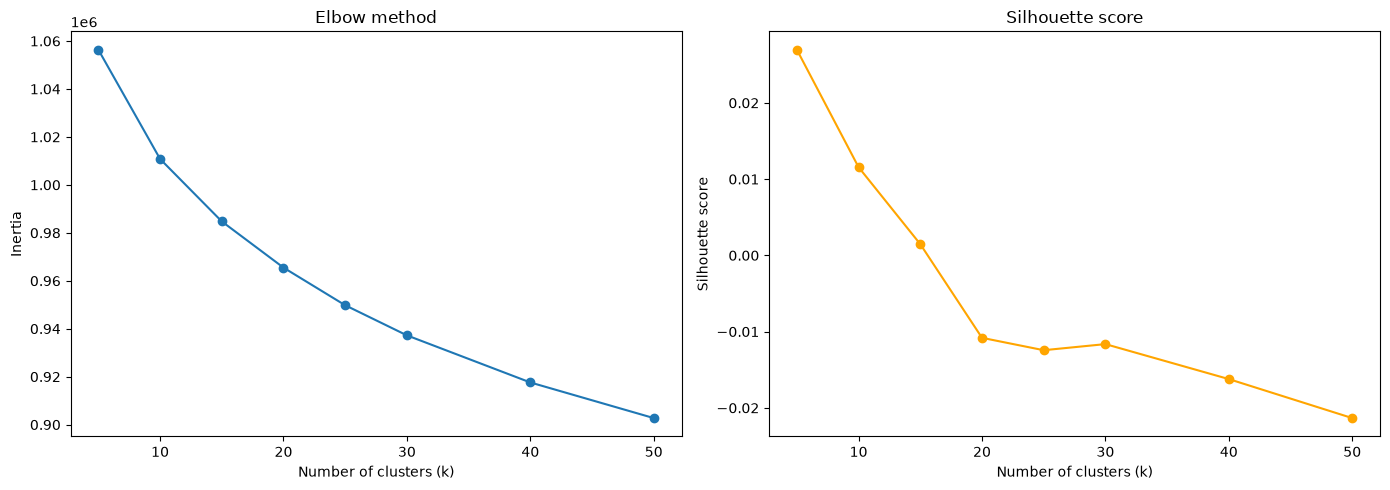

In [11]:
# %% Plot both metrics side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_values, inertias, marker='o')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow method')

axes[1].plot(k_values, silhouette_scores, marker='o', color='orange')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette score')

plt.tight_layout()
plt.show()

In [ ]:
# %% Normalize embeddings to unit length (so Euclidean distance behaves like cosine distance)
from sklearn.preprocessing import normalize

embeddings_norm = normalize(embeddings, norm='l2')

# re-run the same k search on normalized embeddings
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = [5, 10, 15, 20, 25, 30, 40, 50]
inertias_norm = []
silhouette_scores_norm = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(embeddings_norm)
    inertias_norm.append(km.inertia_)
    score = silhouette_score(embeddings_norm, labels, sample_size=5000, random_state=42)
    silhouette_scores_norm.append(score)
    print(f"k={k}: inertia={km.inertia_:.1f}, silhouette={score:.4f}")

# Skip - normalization doesn't work

Clustering after data normalization also gave poor result (silhouette=0.024). Assuming this is curse of dimensionality, so let's try to reduce dimentions before clustering

In [13]:
# %% Reduce dimensionality before clustering
import umap

reducer = umap.UMAP(n_components=15, random_state=42, metric='cosine')
embeddings_reduced = reducer.fit_transform(embeddings)

print("Reduced shape:", embeddings_reduced.shape)

# re-run k search on reduced embeddings
inertias_umap = []
silhouette_scores_umap = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(embeddings_reduced)
    inertias_umap.append(km.inertia_)
    score = silhouette_score(embeddings_reduced, labels, sample_size=5000, random_state=42)
    silhouette_scores_umap.append(score)
    print(f"k={k}: inertia={km.inertia_:.1f}, silhouette={score:.4f}")

/home/roman/Documents/university/thesis/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Reduced shape: (100000, 15)
k=5: inertia=248491.8, silhouette=0.2494
k=10: inertia=164779.5, silhouette=0.2810
k=15: inertia=126574.0, silhouette=0.2973
k=20: inertia=104231.9, silhouette=0.2875
k=25: inertia=88586.1, silhouette=0.3028
k=30: inertia=77744.5, silhouette=0.2954
k=40: inertia=63354.1, silhouette=0.3082
k=50: inertia=54398.5, silhouette=0.3170


Silhouette score increased to 0.3 after dimention reduction. Still increasing - trying bigger number of clusters

In [14]:
# %% Extend the k search to see where silhouette actually plateaus or drops
k_values_extended = [50, 60, 70, 80, 100, 120, 150]
inertias_ext = []
silhouette_scores_ext = []

for k in k_values_extended:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(embeddings_reduced)
    inertias_ext.append(km.inertia_)
    score = silhouette_score(embeddings_reduced, labels, sample_size=5000, random_state=42)
    silhouette_scores_ext.append(score)
    print(f"k={k}: inertia={km.inertia_:.1f}, silhouette={score:.4f}")

k=50: inertia=54398.5, silhouette=0.3170
k=60: inertia=48288.8, silhouette=0.3210
k=70: inertia=43643.2, silhouette=0.3089
k=80: inertia=39580.0, silhouette=0.3095
k=100: inertia=34227.2, silhouette=0.3066
k=120: inertia=30175.9, silhouette=0.3065
k=150: inertia=26184.6, silhouette=0.3048


In [16]:
# %% Extend the k search to see where silhouette actually plateaus or drops
k_values_refined = [52, 55, 57, 59, 60, 62]
inertias_refound = []
silhouette_scores_refound = []

for k in k_values_refined:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(embeddings_reduced)
    inertias_refound.append(km.inertia_)
    score = silhouette_score(embeddings_reduced, labels, sample_size=5000, random_state=42)
    silhouette_scores_refound.append(score)
    print(f"k={k}: inertia={km.inertia_:.1f}, silhouette={score:.4f}")

k=52: inertia=53689.1, silhouette=0.3153
k=55: inertia=51349.7, silhouette=0.3100
k=57: inertia=49989.9, silhouette=0.3221
k=59: inertia=48632.6, silhouette=0.3087
k=60: inertia=48288.8, silhouette=0.3210
k=62: inertia=47197.4, silhouette=0.3192


Even though 60 gives a better result, we still gonna prefer easier model with k = 50. Even bigger numbers didn't work out. k = 50 gives the optimal results

In [17]:
# %% Final clustering with chosen k on UMAP-reduced embeddings
from sklearn.cluster import KMeans

K_FINAL = 50

kmeans_final = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(embeddings_reduced)

df_sample['cluster'] = cluster_labels

print(df_sample['cluster'].value_counts().sort_index())

cluster
0     4224
1     3412
2     2642
3     2504
4     3762
5     2723
6     1294
7     2123
8     1754
9     1342
10    3228
11    1303
12    2755
13    2447
14    2615
15    1704
16    2261
17    2823
18    2092
19    2016
20    2210
21    2388
22    1451
23    1183
24    1238
25    1629
26    2305
27    1281
28    1057
29    2756
30    1264
31    1831
32    1462
33    3755
34    2587
35    1843
36     176
37    3566
38    1957
39    2646
40     624
41    1353
42     827
43    3098
44    1142
45    1614
46     436
47    1542
48      56
49    1699
Name: count, dtype: int64


In [18]:
# %% Inspect sample posts from each cluster to check if they make semantic sense
for cluster_id in sorted(df_sample['cluster'].unique()):
    print(f"\n=== Cluster {cluster_id} (n={sum(df_sample['cluster'] == cluster_id)}) ===")
    samples = df_sample[df_sample['cluster'] == cluster_id]['clean_text'].sample(
        min(5, sum(df_sample['cluster'] == cluster_id)), random_state=42
    )
    for text in samples:
        print(f"  - {text[:100]}")


=== Cluster 0 (n=4224) ===
  - quando jogam com o , faz o jogo como se fosse o último da vida deles.
  - giresunspor > süper lig takımları
  - where my deep hatred for umpires started
  - book your outing at peterculter golf club! for more info on our package deals, visit our website: th
  - hugo kametani makes it 3-0, mavericks. still 24 minutes left in the first half. creighton is getting

=== Cluster 1 (n=3412) ===
  - lol we will never do that 😂😂 she's my lil sister, i like how we interact, heated debates, emotional 
  - garth lagerway “ lo que ayuda a cubrir el vacío de . es que su hermano es el gerente de los visores.
  - juliette já está imune
  - me encantó haber compartido con esa niña hoy en su cumpleaños, nunca olvidaré a su papi y me prometí
  - que lo lleve al taller, que no sea conejito bebé

=== Cluster 2 (n=2642) ===
  - ఒకప్పుడు అది “విశాఖపట్నం＂ ఇప్పుడు పేరు మారింది“విశాఖ పతనం＂ఒక్కటై నిలబడదాం ...! ఒక్కటై పోరాడుదాం ..!ఒ
  - ଓଡ଼ିଆ ଭାଷା ସାହିତ୍ୟ, ସଂସ୍କୃତି କ୍ଷେତ୍ରରେ ଅଧିକ ଗ

Silhouette score shows that the clusters are well divided geometrically, but let's check if they make semantic sense either. We are going to use TF-IDF to see what are the most common words in each cluster. Also we are going to drop stop words.

representation of the most characteristic words of each cluster

In [19]:
# %% Extract top distinguishing words per cluster using TF-IDF, with multilingual stop words removed
from sklearn.feature_extraction.text import TfidfVectorizer

# combine stop word lists for the languages most present in the data

import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

langs = ['english', 'spanish', 'portuguese', 'french', 'german',
            'italian', 'turkish', 'russian', 'arabic', 'indonesian']
multilingual_stopwords = set()
for lang in langs:
    try:
        multilingual_stopwords.update(stopwords.words(lang))
    except OSError:
        pass  # some languages may not be available in this NLTK version

stopword_list = list(multilingual_stopwords)


vectorizer = TfidfVectorizer(max_features=5000, stop_words=stopword_list, min_df=2)
tfidf_matrix = vectorizer.fit_transform(df_sample['clean_text'])
feature_names = vectorizer.get_feature_names_out()

def top_words_for_cluster(cluster_id, n_words=10):
    cluster_mask = df_sample['cluster'] == cluster_id
    cluster_tfidf = tfidf_matrix[cluster_mask.values].mean(axis=0)
    cluster_tfidf = np.asarray(cluster_tfidf).flatten()
    top_indices = cluster_tfidf.argsort()[-n_words:][::-1]
    return [feature_names[i] for i in top_indices]

for cluster_id in sorted(df_sample['cluster'].unique()):
    words = top_words_for_cluster(cluster_id)
    print(f"Cluster {cluster_id} (n={sum(df_sample['cluster'] == cluster_id)}): {', '.join(words)}")

/home/roman/Documents/university/thesis/.venv/lib/python3.14/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/roman/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):
/home/roman/Documents/university/thesis/.venv/lib/python3.14/site-packages/sklearn/feature_extraction/text.py:412: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['baiknya', 'berkali', 'kali', 'kurangnya', 'mata', 'olah', 'sekurang', 'setidak', 'tama', 'tidaknya', 'آمين', 'أب', 'أخ', 'أفعل', 'أفعله', 'ؤلاء', 'إل', 'إم', 'ات', 'اتان', 'ارتد', 'ان', 'انفك', 'برح', 'تان', 'تبد', 'تحو', 'تعل', 'حد', 'حم', 'حي', 'خب', 'ذار', 'سيما', 'صه', 'ظل', 'ظن', 'عد', 'قط', 'مر', 'مكان', 'مكانكن', 'نب', 'هات', 'هب', 'واها', 'وراء'] not

Cluster 0 (n=4224): game, team, win, play, club, time, gol, football, league, games
Cluster 1 (n=3412): mulher, women, baby, like, girl, woman, pra, gay, mãe, get
Cluster 2 (n=2642): கள, indonesia, কর, అన, దర, জন, 임영웅, தல, পর, இர
Cluster 3 (n=2504): go, back, vamos, 10, one, like, time, better, final, pra
Cluster 4 (n=3762): trump, president, presidente, people, vote, democracy, gobierno, biden, myanmar, us
Cluster 5 (n=2723): الله, god, allah, dios, lord, jesus, deus, olsun, اللهم, رب
Cluster 6 (n=1294): drinking, coffee, café, drink, beer, tea, wine, beber, bar, smoke
Cluster 7 (n=2123): day, morning, día, good, καλημέρα, bom, weekend, días, today, semana
Cluster 8 (n=1754): whatsapp, app, internet, phone, iphone, dm, call, free, massage, celular
Cluster 9 (n=1342): video, foto, vídeo, youtube, netflix, fotos, photo, art, photography, picture
Cluster 10 (n=3228): ko, ka, wa, mo, ang, ba, ng, ako, lang, hahaha
Cluster 11 (n=1303): covid, vaccine, vacuna, 19, vacina, virus, pandemia, v

#### Results (100k sample, after boilerplate removal, k=50, UMAP+K-Means)

#### Clear, Thematically Meaningful Clusters

Compared to the 10k run, the larger sample produced noticeably more distinct, human-nameable topics:

*   **Cluster 0:** Sports/football (game, team, win, play, club, gol, football, league)
*   **Cluster 4:** Politics (trump, president, presidente, vote, democracy, biden, myanmar)
*   **Cluster 5, 15, 19:** Religion — split into multiple sub-themes: Cluster 5 is cross-lingual general religion (god/allah/dios/deus/jesus together), Cluster 15 is Islamic-specific (Arabic religious vocabulary), Cluster 19 mixes religion with Indian political/religious figures (rampal, ji)
*   **Cluster 6:** Drinks (coffee, café, beer, tea, wine, drinking)
*   **Cluster 7:** Greetings/daily wishes (day, morning, good morning in multiple languages — καλημέρα, bom día)
*   **Cluster 9:** Photography/video sharing (video, foto, youtube, netflix, photography)
*   **Cluster 11:** COVID/vaccination — again the clearest cross-lingual topic (covid, vaccine, vacuna, vacina, pandemia — same word in five languages)
*   **Cluster 14:** Money/finance (money, dinero, bitcoin, bank, business)
*   **Cluster 21:** Urban infrastructure (city, road, traffic, car, property, gas)
*   **Cluster 22:** Latin American countries (brasil, venezuela, nigeria, colombia, mexico — likely a geography/naming cluster rather than a topic per se)
*   **Cluster 23:** Weather (snow, rain, cold, winter, wind)
*   **Cluster 24:** Social media meta (twitter, tweet, facebook, instagram, followers)
*   **Cluster 25:** Sleep/night (dormir, sleep, night, sueño, bed)
*   **Cluster 26:** Food (food, comer, eat, pizza, chocolate)
*   **Cluster 28:** Health/medical (hospital, doctor, health, medical, dose)
*   **Cluster 30:** TV/movies (show, watch, tv, movie, episode)
*   **Cluster 31:** Nature/beach imagery (beach, sunset, playa, mar, moon)
*   **Cluster 32:** Music (music, song, album, dj, podcast)
*   **Cluster 40:** Birthdays (birthday, valentine, cumpleaños, feliz)
*   **Cluster 41:** Profanity/insults (fuck, puta, bitch, shit — a distinct "register" cluster)
*   **Cluster 43:** Social justice/news (news, justice, police, black, media)
*   **Cluster 44:** New Year (2021, year, new, año, feliz año)
*   **Cluster 46:** Pets/animals (dog, perro, goat, dogs, horse)
*   **Cluster 47:** Life/books (life, vida, book, read, world, story)

This is roughly **20+ out of 50 clusters** with a clearly nameable topic — a substantial improvement over the 10k run (where only ~10 out of 25 were clear). This supports the hypothesis that more data helps the clustering separate topics more distinctly.

#### Still Mixed / Noise Clusters

*   **Clusters 1, 3, 10, 12, 16, 29, 33, 34, 37, 38, 39, 49:** top words are generic conversational fillers, pronouns, or laughter transliterations (ko, ka, lol, jajajaja, hahaha, like, pra, tá) rather than a topic. These are short, purely conversational/reactive posts with no distinct subject — likely an irreducible "noise" category for this kind of data.
*   **Cluster 2, 45:** dominated by non-Latin script tokens with little shared semantic thread visible from top words alone (Telugu/Odia/Korean/Hindi/Chinese mixed) — may indicate the vectorizer/stopword list under-serves these scripts rather than a genuinely incoherent cluster; worth flagging as a limitation of the TF-IDF-based validation step (stopword lists are Latin/major-language-biased).
*   **Cluster 48:** very small (n=56) — tattoos; likely a genuine but under-represented niche topic, not noise.
*   **Cluster 36:** very small (n=176) — cats/pets mixed with unrelated fragments; borderline.

#### Comparison: 10k vs 100k

| | 10k sample | 100k sample (post boilerplate removal) |
|---|---|---|
| Best silhouette (after UMAP) | ~0.31 (k=25) | ~0.32 (k=50, plateau 40–62) |
| Clearly nameable clusters | ~10 / 25 (40%) | ~20+ / 50 (40%+, but more granular topics: religion and photography split into sub-themes not visible at 10k) |
| Noise clusters | present, mostly emotional/conversational | still present, similar character, but now cleanly separated from bot/template artifacts (removed beforehand) |

**Conclusion:** Increasing sample size from 10k to 100k did not fundamentally change the *proportion* of interpretable vs. noisy clusters, but it did increase the *granularity and stability* of the clear topics — e.g. religion split into general/Islamic/Indian-political sub-clusters, and photography/video emerged as its own distinct topic only at the larger scale. This is itself a useful finding for the thesis: sample size affects topic granularity more than it affects the fundamental "signal vs. noise" ratio in short, informal social media text.

A separate, important methodological finding: a non-trivial fraction of "topics" found in early clustering runs were not real content at all, but **automated/bot-generated templates** (check-in apps, photo-sharing bots, hashtag spam campaigns, weather/earthquake bots) in multiple languages. These had to be identified iteratively (via repeated-prefix analysis and manual inspection of cluster contents) and removed before the clustering results could be considered valid — this is a concrete, reportable data-cleaning contribution, not just a footnote.

In [20]:
# %% Save the fitted UMAP reducer and KMeans model to disk for later reuse
import joblib

joblib.dump(reducer, 'umap_reducer_100k.joblib')
joblib.dump(kmeans_final, 'kmeans_k50_100k.joblib')

print("UMAP reducer and KMeans model saved.")

UMAP reducer and KMeans model saved.
